# Figure 2: the ANN

Diagram of the feed-forward network used throughout the paper (`models/ann_model.keras`, trained in `02_training_and_testing_the_ann.ipynb`), drawn with [ann_graphic_generator](https://github.com/vanbreugel-lab/ann_graphic_generator).

**Requires** `02_training_and_testing_the_ann.ipynb` (it reads `models/ann_model.keras`). The diagram is not typed in by hand: the layer sizes are read from the saved model, and the input and output names from notebook 02's code. The notebook stops if they no longer match what the figure says (see *Network*).

**Network** (checked below): 4 inputs → 3 hidden layers of 30 ReLU units → 2 linear units, normalised to unit length.
- **Inputs**, in the model's order: groundspeed and groundspeed direction, airspeed and airspeed direction (`groundspeed`, `groundspeed_angle`, `airspeed`, `airspeed_angle` from `augment_fly_trajectory`). Speeds are in m/s, and directions are in rad in the horizontal plane, in the wind frame (wind toward +x). They are not rescaled.
- **Outputs**: `heading_angle_x` = cos θ and `heading_angle_y` = sin θ of the body heading θ. The last layer (`UnitNormalization`) puts them on the unit circle, and θ = atan2(sin θ, cos θ).

**Output**: `publication_figures/figure_2.svg`, a [figurefirst](https://github.com/FlyRanch/figurefirst) layout on a letter page, built like Figures 1 and 3–6 but one column wide. Its template layer ("Layer 1", hidden in the output) holds one rectangle, the figurefirst axis `network` in the figurefirst figure `ann`. The notebook creates the layout if it does not exist and redraws the diagram into the `ann` layer on every run. Changes made in Inkscape to the rectangle (moving or resizing it) or to other layers are kept.

**Graphics**: the package's layered (feed-forward) mode, with every connection drawn. The hidden layers are too large to draw in full: each is drawn as `MAX_NODES` nodes with an ellipsis (⋮) in the middle and labelled with its real size (the package's `--max-nodes` and `--show-counts truncated` options). The input and output nodes are each labelled with their quantity.

**Installing the package**: it pins numpy ≥ 2.4 and matplotlib ≥ 3.11, which this environment cannot have (TensorFlow), but it runs with the versions here. Install it without its dependencies, plus networkx, which it imports (see `requirements.txt`).

## Setup

In [1]:
import ast
import json
import os
import re
import warnings
from unittest import mock

import keras   # before anything that imports pandas/pyarrow (see CLAUDE.md, TensorFlow deadlock)
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties
from matplotlib.textpath import TextPath
from IPython.display import SVG, display

import ann_graphic_generator.draw_network as dn

with warnings.catch_warnings():
    warnings.simplefilter('ignore')   # figurefirst emits SyntaxWarnings on import under Python 3.12
    import figurefirst as fifi

plt.rcParams['svg.fonttype'] = 'none'   # keep text editable in Inkscape
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']

LAYOUT_PATH = '../publication_figures/figure_2.svg'
MODEL_PATH = '../models/ann_model.keras'
TRAINING_NOTEBOOK = '../notebooks/02_training_and_testing_the_ann.ipynb'

## Network

The layer sizes come from the saved model: its input size, then the units of each `Dense` layer. The checks stop the notebook if the architecture is no longer ReLU hidden layers, a linear output layer and a `UnitNormalization` layer.

The input and output names come from notebook 02: `ann_input_names`, and the columns of `y_train`. Each one must have a label below. A new name raises a `KeyError`, so the figure cannot silently mislabel a changed model. The labels follow the model's order, top to bottom; the direction labels take two lines to leave the hidden layers room.

In [2]:
model = keras.models.load_model(MODEL_PATH, compile=False)
dense = [layer for layer in model.layers if isinstance(layer, keras.layers.Dense)]
LAYERS = [model.input_shape[-1]] + [layer.units for layer in dense]
assert [layer.activation.__name__ for layer in dense] == ['relu'] * (len(dense) - 1) + ['linear'], 'expected ReLU hidden layers and a linear output layer'
assert isinstance(model.layers[-1], keras.layers.UnitNormalization), 'expected a UnitNormalization output layer'

nb02 = json.load(open(TRAINING_NOTEBOOK))
src = '\n'.join(''.join(cell['source']) for cell in nb02['cells'] if cell['cell_type'] == 'code')
INPUTS = ast.literal_eval(re.search(r'^ann_input_names = (\[.*?\])', src, re.M).group(1))
OUTPUTS = ast.literal_eval(re.search(r'^y_train = train_all\[(\[.*?\])\]', src, re.M).group(1))
assert (len(INPUTS), len(OUTPUTS)) == (LAYERS[0], LAYERS[-1]), 'notebook 02 and the saved model disagree on the number of inputs/outputs'

INPUT_LABELS = {'groundspeed': 'Groundspeed', 'groundspeed_angle': 'Groundspeed\ndirection',
                'airspeed': 'Airspeed', 'airspeed_angle': 'Airspeed\ndirection'}
OUTPUT_LABELS = {'heading_angle_x': 'cos θ', 'heading_angle_y': 'sin θ'}
input_labels = [INPUT_LABELS[name] for name in INPUTS]
output_labels = [OUTPUT_LABELS[name] for name in OUTPUTS]

print('layers:', ' → '.join(map(str, LAYERS)))
print('inputs:', {name: label.replace('\n', ' ') for name, label in zip(INPUTS, input_labels)})
print('outputs:', dict(zip(OUTPUTS, output_labels)))

layers: 4 → 30 → 30 → 30 → 2
inputs: {'groundspeed': 'Groundspeed', 'groundspeed_angle': 'Groundspeed direction', 'airspeed': 'Airspeed', 'airspeed_angle': 'Airspeed direction'}
outputs: {'heading_angle_x': 'cos θ', 'heading_angle_y': 'sin θ'}


## Layout

Letter page in Inkscape's default user units (96 px/in), with the diagram one column wide (`FIG_W`), at the top left of the panel area of Figures 1 and 3–6. The rectangle is the whole axis, labels included: the diagram is drawn in inches inside it, so it keeps its proportions only if the rectangle is resized in proportion. Set `OVERWRITE_LAYOUT = True` to regenerate the layout from these constants. This discards any edits made to the file in Inkscape.

In [3]:
OVERWRITE_LAYOUT = False

PX_PER_IN = 96
PAGE_W, PAGE_H = 8.5, 11.0         # in
FIG_W, FIG_H = 3.25, 2.4           # in: one column wide
LEFT, TOP = 1.0, 1.0               # in, as Figures 1 and 3-6 (6.5 in panels centred on the page)


def panel_rects():
    '''{figure name: [(axis name, x, y, w, h), ...]} in inches from the page's top left corner'''
    return {'ann': [('network', LEFT, TOP, FIG_W, FIG_H)]}


def group_svg(figure, rects):
    '''A figurefirst figure: a group of rectangles, each a figurefirst axis'''
    out = [f'    <g id="{figure}_template">', f'      <figurefirst:figure figurefirst:name="{figure}" />']
    for name, x, y, w, h in rects:
        out.append(f'      <rect id="{name}" x="{x * PX_PER_IN:g}" y="{y * PX_PER_IN:g}" width="{w * PX_PER_IN:g}" '
                   f'height="{h * PX_PER_IN:g}" style="fill:none;stroke:#000000;stroke-width:1">\n'
                   f'        <figurefirst:axis figurefirst:name="{name}" />\n'
                   f'      </rect>')
    return '\n'.join(out) + '\n    </g>\n'


def make_layout_svg(path):
    groups = ''.join(group_svg(figure, rects) for figure, rects in panel_rects().items())
    svg = f'''<?xml version="1.0" encoding="UTF-8" standalone="no"?>
<svg
   xmlns="http://www.w3.org/2000/svg"
   xmlns:svg="http://www.w3.org/2000/svg"
   xmlns:inkscape="http://www.inkscape.org/namespaces/inkscape"
   xmlns:sodipodi="http://sodipodi.sourceforge.net/DTD/sodipodi-0.dtd"
   xmlns:figurefirst="http://flyranch.github.io/figurefirst/"
   width="{PAGE_W}in"
   height="{PAGE_H}in"
   viewBox="0 0 {PAGE_W * PX_PER_IN:g} {PAGE_H * PX_PER_IN:g}"
   version="1.1"
   id="svg1">
  <sodipodi:namedview id="namedview1" inkscape:document-units="in" />
  <g inkscape:groupmode="layer" inkscape:label="Layer 1" id="layer1">
{groups}  </g>
</svg>
'''
    with open(path, 'w') as f:
        f.write(svg)


os.makedirs(os.path.dirname(LAYOUT_PATH), exist_ok=True)
if OVERWRITE_LAYOUT or not os.path.exists(LAYOUT_PATH):
    make_layout_svg(LAYOUT_PATH)
    print(f'Wrote layout {LAYOUT_PATH}')
else:
    print(f'Using existing layout {LAYOUT_PATH}')

Wrote layout ../publication_figures/figure_2.svg


## Plotting

Font size and line widths follow Figures 1 and 3–6. The package places the nodes (`layered_positions`, which also leaves the slot for each ellipsis) and draws the diagram (`draw`). `draw` normally makes its own figure and saves it as an SVG, so `OnAxis` stands in for pyplot while it runs and hands it the figurefirst axis instead. `draw` then sets that axis to the diagram's coordinates (inches, from 0 to the axis's size). The hidden-layer size labels are made as the package's `--show-counts truncated` makes them, with room kept for them below the nodes. The layer names and the input and output labels are added around the diagram, in room kept free at the top and sides.

In [4]:
FONTSIZE = 7
COUNT_FONTSIZE = FONTSIZE - 1      # hidden-layer size labels
MAX_NODES = 6                      # nodes drawn per hidden layer, around an ellipsis
RADIUS = 0.045                     # node radius (in)
LINEWIDTH = 0.5                    # node outlines (pt)
EDGE_COLOR = '0.55'                # connections
GAP = 0.06                         # node outline to its label (in)
HEAD_H = 0.2                       # room above the nodes for the layer names (in)
NOTE = 'θ: heading'           # under the output labels


def text_width(text, size):
    '''Approximate width of text in inches (the SVG viewer may substitute its own font)'''
    prop = FontProperties(family='sans-serif', size=size)
    return max(TextPath((0, 0), line, prop=prop).get_extents().width for line in text.split('\n')) / 72


class OnAxis:
    '''Stands in for pyplot (and the figure it makes) inside dn.draw, so the diagram is drawn into ax and not saved'''
    def __init__(self, ax): self.ax = ax
    def figure(self, figsize): return self
    def add_axes(self, rect): return self.ax
    def savefig(self, *args, **kwargs): pass
    def close(self, fig): pass


def plot_network(ax, width, height):
    margin = 2 * RADIUS   # the package's default
    counts = [f'({n} nodes)' if n > MAX_NODES else None for n in LAYERS]
    bottom = RADIUS + 1.2 * COUNT_FONTSIZE / 72   # room below the nodes for the counts, as the package keeps
    sides = (max(text_width(t, FONTSIZE) for t in input_labels) + GAP + RADIUS,
             max(text_width(t, FONTSIZE) for t in output_labels + [NOTE]) + GAP + RADIUS)
    pos, ellipses = dn.layered_positions(LAYERS, width, height - HEAD_H, margin, MAX_NODES, bottom, sides)
    edges = dn.layered_edges([len(p) for p in pos], 1.0, np.random.default_rng(0))   # density 1: every connection
    y = margin + bottom - 1.5 * RADIUS
    labels = [(p[0, 0], y, t) for p, t in zip(pos, counts) if t]
    with mock.patch.object(dn, 'plt', OnAxis(ax)):
        dn.draw(np.vstack(pos), edges, width, height, RADIUS, out=f'{FIGURE}/{AXIS}', edge_color=EDGE_COLOR,
                linewidth=LINEWIDTH, ellipses=ellipses, labels=labels, font_size=COUNT_FONTSIZE)
    for t in ax.texts:
        t.set_color('black')   # draw colours its labels like the connections

    kw = dict(fontsize=FONTSIZE, va='center')
    for (x, y), label in zip(pos[0], input_labels):
        ax.text(x - RADIUS - GAP, y, label, ha='right', **kw)
    for (x, y), label in zip(pos[-1], output_labels):
        ax.text(x + RADIUS + GAP, y, label, ha='left', **kw)
    x, y = pos[-1][-1]
    ax.text(x + RADIUS + GAP, y - 2.5 * RADIUS, NOTE, ha='left', va='top', fontsize=COUNT_FONTSIZE)

    hidden = pos[len(pos) // 2][0, 0] if len(pos) % 2 else (pos[1][0, 0] + pos[-2][0, 0]) / 2
    for x, name in ((pos[0][0, 0], 'Input'), (hidden, 'Hidden layers (ReLU)'), (pos[-1][0, 0], 'Output')):
        ax.text(x, height, name, ha='center', va='top', fontsize=FONTSIZE)

## Draw the figure

The diagram is written into the `ann` layer of `publication_figures/figure_2.svg`, which is cleared first.

saved ann/network: 24 nodes, 108 edges


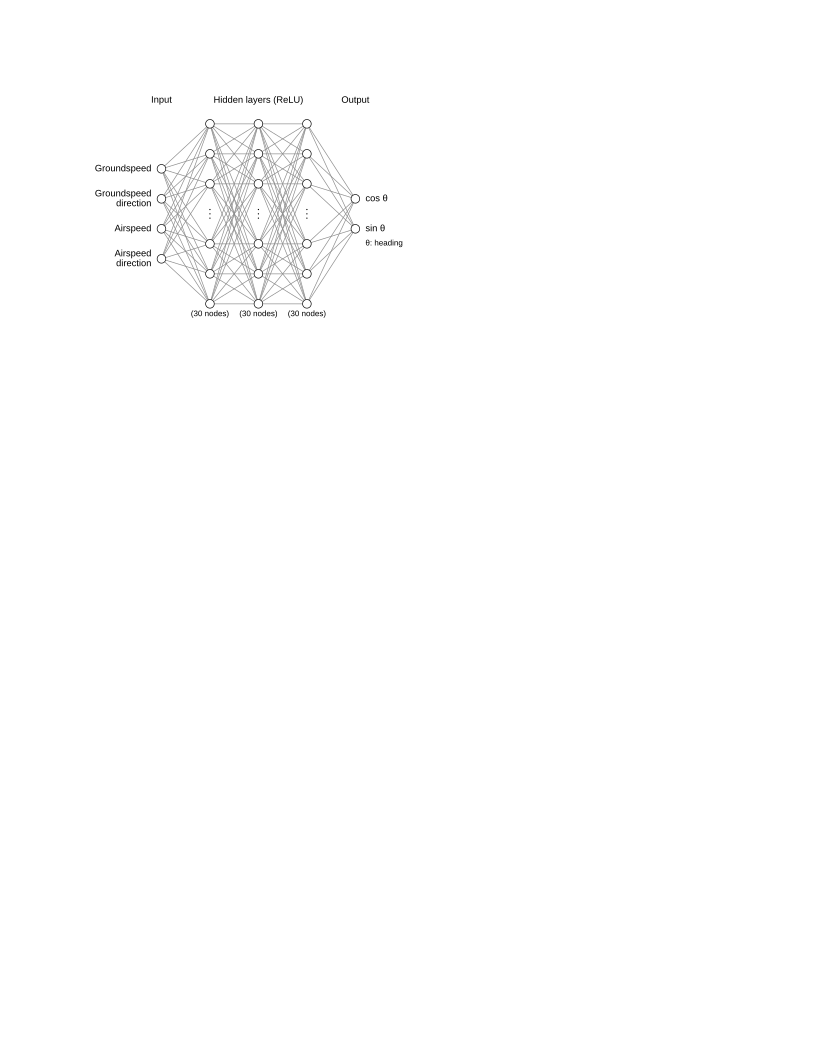

In [5]:
FIGURE, AXIS = 'ann', 'network'
layout = fifi.FigureLayout(LAYOUT_PATH, autogenlayers=True, make_mplfigures=True)
ax = layout.axes[(FIGURE, AXIS)]
w, h = (ax.get_window_extent().transformed(ax.figure.dpi_scale_trans.inverted()).size)   # the rectangle's size (in)
plot_network(ax, w, h)
layout.append_figure_to_layer(layout.figures[FIGURE], FIGURE, cleartarget=True)

layout.write_svg(LAYOUT_PATH)
plt.close('all')
display(SVG(LAYOUT_PATH))